In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import os
from statsmodels.stats.multitest import multipletests
from pathlib import Path

In [8]:
# 1. Where you put the GitHub directory (your parent workspace folder)
base_dir = Path(r'C:\Users\jmf7ak\OneDrive - University of Virginia\25_SPRING\Evolution_paper')

# 2. The GitHub repository name
repo_name = 'media_evolution_paper'

In [10]:
mut_file = base_dir / repo_name / 'data' / 'mutation_matrix.csv'
df = pd.read_csv(mut_file)

df.columns = df.columns.str.strip()

# - 'MIC*' is TOB MIC
# - 'MIC*2' is CIP MIC
df = df.rename(columns={
    'MIC*': 'TOB_MIC',
    'MIC*2': 'CIP_MIC'
})

C:\Users\jmf7ak\AppData\Local\Temp\ipykernel_36756\3158192083.py:2: DtypeWarning: Columns (9,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(mut_file)


In [12]:
for drug in ['TOB', 'CIP']:
    df[f'{drug}_MIC'] = pd.to_numeric(df[f'{drug}_MIC'].astype(str).str.replace(r'[^\d.]', '', regex=True), errors='coerce')
    df[f'{drug}_log2'] = np.log2(df[f'{drug}_MIC'])

# 3. Dynamic Loci Detection
# Exclude known metadata and MIC columns to isolate ALL mutation columns
metadata_cols = ['Sample', 'Source', 'Isolate', 'Supplier (Geographic orig)', 
                 'TOB', 'TOB_MIC', 'TOB_log2', 'CIP', 'CIP_MIC', 'CIP_log2', 
                 'MEM', 'MIC*3', 'CAZ', 'MIC*4']

mutation_cols = [c for c in df.columns if c not in metadata_cols and not c.startswith('Unnamed')]

print(f"Detected {len(mutation_cols)} total mutation loci across all genes.")

Detected 16371 total mutation loci across all genes.


In [14]:
# 4. Gene-Level Aggregation (Summing mutations per gene per strain)
# Extract gene names from columns formatted like 'geneName_position'
gene_names = set(col.split('_')[0] for col in mutation_cols if '_' in col)

# Dictionary to store new aggregated series
gene_totals = {}

for gene in gene_names:
    gene_cols = [c for c in mutation_cols if c.startswith(f'{gene}_')]
    if gene_cols:
        # Compute row-wise sums for this gene's variants
        gene_totals[f'{gene}_total_mutations'] = df[gene_cols].sum(axis=1)

# Concatenate all gene mutation totals to the main DataFrame at once
df = pd.concat([df, pd.DataFrame(gene_totals, index=df.index)], axis=1)

In [16]:
results = []

for drug in ['CIP', 'TOB']:
    log2_col = f'{drug}_log2'
    
    for mut in mutation_cols:
        sub = df[[mut, log2_col]].dropna()
        wt_log = sub[sub[mut] == 0][log2_col]
        mut_log = sub[sub[mut] == 1][log2_col]
        
        if len(wt_log) >= 2 and len(mut_log) >= 2:
            # Mann-Whitney on log2 MICs
            stat, p_val = mannwhitneyu(wt_log, mut_log, alternative='two-sided')
            
            med_wt = wt_log.median()
            med_mut = mut_log.median()
            
            # True delta log2 MIC (difference in log2 medians)
            delta_log2_mic = med_mut - med_wt
            
            results.append({
                'Drug': drug,
                'Locus': mut,
                'Gene': mut.split('_')[0] if '_' in mut else mut,
                'p_value': p_val,
                'delta_log2_mic': delta_log2_mic,
                'WT_median_log2': med_wt,
                'Mut_median_log2': med_mut,
                'WT_count': len(wt_log),
                'Mut_count': len(mut_log)
            })

stats_df = pd.DataFrame(results)

# Apply Benjamini-Hochberg FDR correction per drug group
stats_df['fdr_qval'] = 1.0
for drug in ['CIP', 'TOB']:
    mask = stats_df['Drug'] == drug
    if mask.any():
        p_vals = stats_df.loc[mask, 'p_value']
        _, q_vals, _, _ = multipletests(p_vals, method='fdr_bh')
        stats_df.loc[mask, 'fdr_qval'] = q_vals

stats_df['neg_log10_p'] = -np.log10(stats_df['p_value'].replace(0, np.nan))
stats_df['neg_log10_fdr'] = -np.log10(stats_df['fdr_qval'].replace(0, np.nan))

In [17]:
# Create binary presence/absence columns for each gene
gene_cols = []
for gene in gene_names:
    total_col = f'{gene}_total_mutations'
    if total_col in df.columns:
        binary_col = f'{gene}_any_mut'
        df[binary_col] = (df[total_col] > 0).astype(int)
        gene_cols.append(binary_col)

# Run the exact same loop using gene_cols instead of mutation_cols
gene_results = []
for drug in ['CIP', 'TOB']:
    log2_col = f'{drug}_log2'
    for g_col in gene_cols:
        sub = df[[g_col, log2_col]].dropna()
        wt_log = sub[sub[g_col] == 0][log2_col]
        mut_log = sub[sub[g_col] == 1][log2_col]
        
        if len(wt_log) >= 2 and len(mut_log) >= 3:  # Slightly stricter N requirement
            stat, p_val = mannwhitneyu(wt_log, mut_log, alternative='two-sided')
            med_wt, med_mut = wt_log.median(), mut_log.median()
            
            gene_results.append({
                'Drug': drug,
                'Gene': g_col.replace('_any_mut', ''),
                'p_value': p_val,
                'delta_log2_mic': med_mut - med_wt,
                'WT_count': len(wt_log),
                'Mut_count': len(mut_log)
            })

gene_stats_df = pd.DataFrame(gene_results)

# Apply FDR correction
gene_stats_df['fdr_qval'] = 1.0
for drug in ['CIP', 'TOB']:
    mask = gene_stats_df['Drug'] == drug
    if mask.any():
        _, q_vals, _, _ = multipletests(gene_stats_df.loc[mask, 'p_value'], method='fdr_bh')
        gene_stats_df.loc[mask, 'fdr_qval'] = q_vals

gene_stats_df['neg_log10_fdr'] = -np.log10(gene_stats_df['fdr_qval'].replace(0, np.nan))

C:\Users\jmf7ak\AppData\Local\Temp\ipykernel_36756\2411869453.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[binary_col] = (df[total_col] > 0).astype(int)
C:\Users\jmf7ak\AppData\Local\Temp\ipykernel_36756\2411869453.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[binary_col] = (df[total_col] > 0).astype(int)
C:\Users\jmf7ak\AppData\Local\Temp\ipykernel_36756\2411869453.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perform

In [18]:
# Significant hits shift MIC by at least 1 doubling dilution
sig_hits = gene_stats_df[
    (gene_stats_df['fdr_qval'] < 0.05) & 
    (gene_stats_df['delta_log2_mic'].abs() >= 1.0)
].sort_values(by=['Drug', 'fdr_qval'])

print("Top Statistically Significant Targets:")
print(sig_hits[['Drug', 'Gene', 'delta_log2_mic', 'fdr_qval', 'Mut_count']])

Top Statistically Significant Targets:
    Drug    Gene  delta_log2_mic  fdr_qval  Mut_count
55   CIP    hcp2             3.0  0.000008         96
98   CIP     tap             3.0  0.000008        102
4    CIP    cmrA            -3.0  0.000010        335
73   CIP  vgrG14             3.0  0.000010         99
3    CIP   cupA2             2.0  0.000020        201
..   ...     ...             ...       ...        ...
217  TOB    rhlR            -2.0  0.028575        309
196  TOB   fusA2             1.0  0.037855        386
193  TOB     ada             1.0  0.039590        392
201  TOB    hcnB             1.0  0.046955        388
149  TOB    tsi3             1.0  0.049483        397

[185 rows x 5 columns]


<>:33: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\l'
C:\Users\jmf7ak\AppData\Local\Temp\ipykernel_36756\321805001.py:33: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel('$\Delta \log_2(\mathrm{MIC})$ (Mutant - WT Median)')
C:\Users\jmf7ak\AppData\Local\Temp\ipykernel_36756\321805001.py:34: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel('$-\log_{10}(\mathrm{FDR\ } q\mathrm{-value})$')


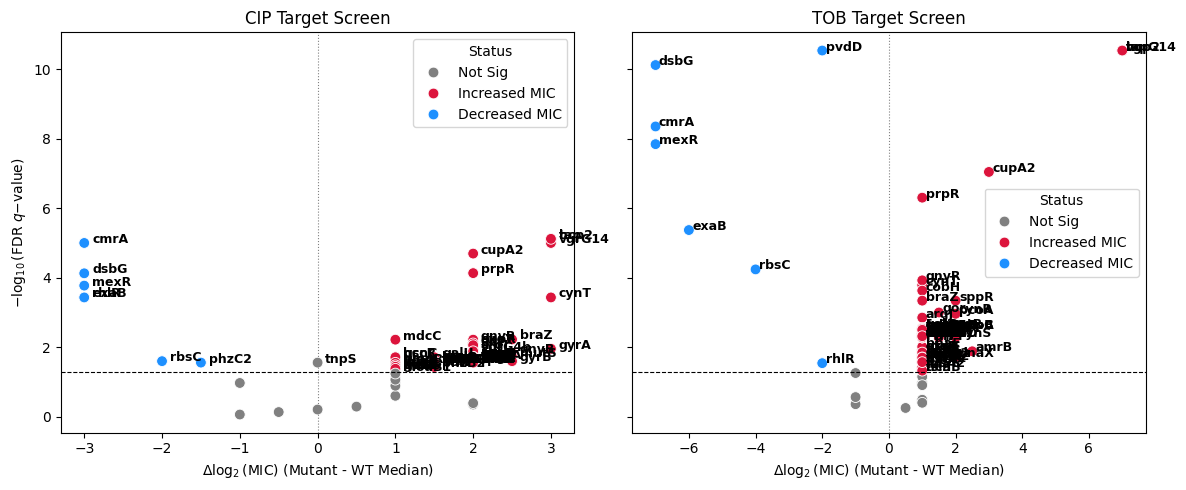

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for i, drug in enumerate(['CIP', 'TOB']):
    sub = gene_stats_df[gene_stats_df['Drug'] == drug].copy()
    ax = axes[i]
    
    # Classify points
    sub['Status'] = 'Not Sig'
    sub.loc[(sub['fdr_qval'] < 0.05) & (sub['delta_log2_mic'] > 0), 'Status'] = 'Increased MIC'
    sub.loc[(sub['fdr_qval'] < 0.05) & (sub['delta_log2_mic'] < 0), 'Status'] = 'Decreased MIC'
    
    palette = {'Not Sig': 'grey', 'Increased MIC': 'crimson', 'Decreased MIC': 'dodgerblue'}
    
    sns.scatterplot(
        data=sub, x='delta_log2_mic', y='neg_log10_fdr', 
        hue='Status', palette=palette, s=60, ax=ax
    )
    
    # Label top hit genes
    top_genes = sub[sub['fdr_qval'] < 0.05]
    for _, row in top_genes.iterrows():
        ax.text(
            row['delta_log2_mic'] + 0.1, row['neg_log10_fdr'], 
            row['Gene'], fontsize=9, fontweight='bold'
        )
        
    ax.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.8)
    ax.axvline(0, color='grey', linestyle=':', linewidth=0.8)
    ax.set_title(f'{drug} Target Screen')
    ax.set_xlabel('$\Delta \log_2(\mathrm{MIC})$ (Mutant - WT Median)')
    ax.set_ylabel('$-\log_{10}(\mathrm{FDR\ } q\mathrm{-value})$')

plt.tight_layout()
plt.show()

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Map target genes and conditions
target_genes = {
    'gyrA': 'Aerobic',
    'gyrB': 'Aerobic',
    'cobJ': 'Aerobic',
    'orfN': 'Aerobic',
    'ptsP': 'Aerobic',
    'fusA': 'Anaerobic',
    'PA14_12490': 'Anaerobic',
    'mexS': 'Both',
    'mexS': 'Both',
    'mexT': 'Both',
    'nfxB': 'Both'
}

# 2. Filter gene-level results for target genes & annotate condition
target_df = gene_stats_df[gene_stats_df['Gene'].isin(target_genes.keys())].copy()
target_df['Condition'] = target_df['Gene'].map(target_genes)

# Convert log2 fold-change to linear fold-change for intuitive reporting
target_df['Fold_Change_MIC'] = 2 ** target_df['delta_log2_mic']

# Reorder columns for clean display
display_cols = [
    'Drug', 'Gene', 'Condition', 'delta_log2_mic', 'Fold_Change_MIC', 
    'p_value', 'fdr_qval', 'WT_count', 'Mut_count'
]
summary_table = target_df[display_cols].sort_values(by=['Drug', 'fdr_qval'])

print("=== TARGET GENES MIC IMPACT SUMMARY ===")
print(summary_table.to_string(index=False))

=== TARGET GENES MIC IMPACT SUMMARY ===
Drug Gene Condition  delta_log2_mic  Fold_Change_MIC  p_value  fdr_qval  WT_count  Mut_count
 CIP gyrA   Aerobic             3.0         8.000000 0.001751  0.010995        11        402
 CIP ptsP   Aerobic             2.0         4.000000 0.009965  0.025023        15        398
 CIP gyrB   Aerobic             2.5         5.656854 0.009586  0.025023        12        401
 CIP cobJ   Aerobic             1.5         2.828427 0.019754  0.027903        14        399
 CIP nfxB      Both             1.5         2.828427 0.014527  0.027903        26        387
 CIP fusA Anaerobic             1.5         2.828427 0.019754  0.027903        14        399
 CIP mexS      Both             1.0         2.000000 0.031931  0.041473        18        395
 TOB ptsP   Aerobic             1.0         2.000000 0.001613  0.004142        15        398
 TOB cobJ   Aerobic             1.0         2.000000 0.003160  0.005175        14        399
 TOB fusA Anaerobic           

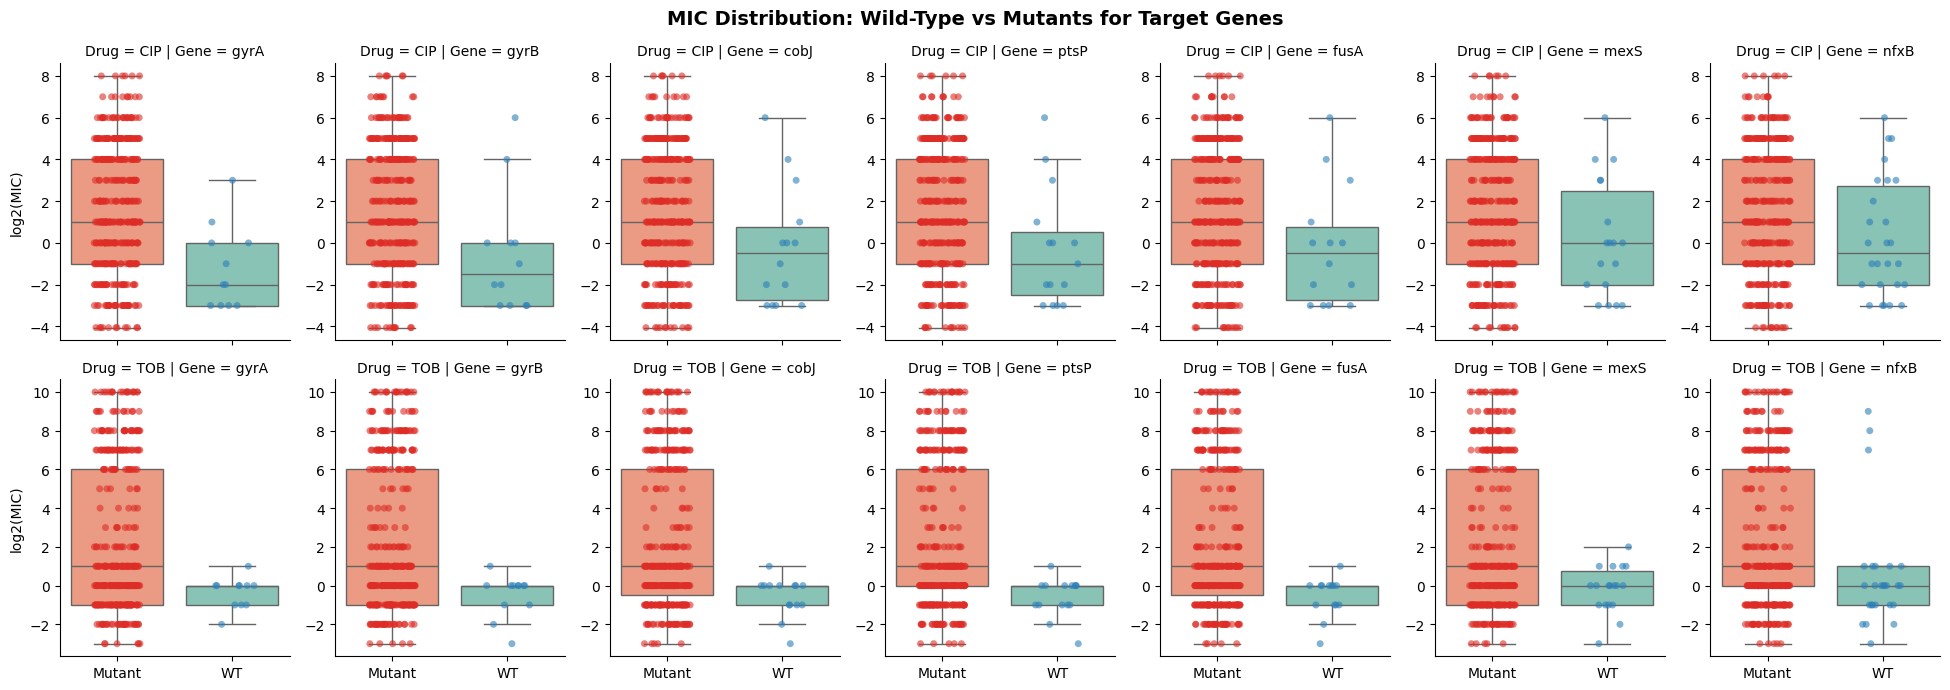

In [21]:
# Melt dataset for visualization if binary gene columns exist in df
target_binary_cols = [f'{g}_any_mut' for g in target_genes.keys() if f'{g}_any_mut' in df.columns]

plot_data = []
for drug in ['CIP', 'TOB']:
    log2_col = f'{drug}_log2'
    if log2_col not in df.columns:
        continue
    for gene, cond in target_genes.items():
        b_col = f'{gene}_any_mut'
        if b_col in df.columns:
            sub = df[[b_col, log2_col]].dropna().copy()
            sub['Gene'] = gene
            sub['Condition'] = cond
            sub['Drug'] = drug
            sub['Genotype'] = sub[b_col].map({0: 'WT', 1: 'Mutant'})
            sub['log2_MIC'] = sub[log2_col]
            plot_data.append(sub)

if plot_data:
    viz_df = pd.concat(plot_data, ignore_index=True)

    # Plot Log2 MIC distributions across target genes
    g = sns.catplot(
        data=viz_df,
        x='Genotype',
        y='log2_MIC',
        col='Gene',
        row='Drug',
        hue='Genotype',
        kind='box',
        palette={'WT': '#7fcdbb', 'Mutant': '#fc9272'},
        height=3.5,
        aspect=0.8,
        sharey=False,
        fliersize=0
    )
    
    # Overlay individual data points
    g.map_dataframe(
        sns.stripplot,
        x='Genotype',
        y='log2_MIC',
        hue='Genotype',
        palette={'WT': '#2c7fb8', 'Mutant': '#de2d26'},
        alpha=0.6,
        jitter=0.2,
        size=5
    )
    
    g.set_axis_labels("", "log2(MIC)")
    g.fig.subplots_adjust(top=0.9)
    g.fig.suptitle("MIC Distribution: Wild-Type vs Mutants for Target Genes", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

target_genes = [
    "hmgA", "mpl", "hcp2", "mexR", 
    "PA14_12490", "gyrA", "gyrB", "mexS", 
    "nfxB", "fusA1", "cobJ", "orfN", "ptsP"
]

# Filter stats_df for locus-level mutations within target genes
# that significantly INCREASE MIC (delta_log2_mic > 0)
sig_increasing_muts = stats_df[
    (stats_df['Gene'].isin(target_genes)) & 
    (stats_df['fdr_qval'] < 0.05) & 
    (stats_df['delta_log2_mic'] > 0)
].copy()

# Add linear fold change (2^delta)
sig_increasing_muts['Fold_Increase'] = 2 ** sig_increasing_muts['delta_log2_mic']

# Sort by largest MIC increase
sig_increasing_muts = sig_increasing_muts.sort_values(by=['Drug', 'delta_log2_mic'], ascending=[True, False])

print(f"Found {len(sig_increasing_muts)} locus-level mutations significantly increasing MIC:")
print(sig_increasing_muts[['Drug', 'Locus', 'Gene', 'delta_log2_mic', 'Fold_Increase', 'fdr_qval', 'Mut_count']])

Found 185 locus-level mutations significantly increasing MIC:
      Drug         Locus  Gene  delta_log2_mic  Fold_Increase      fdr_qval  \
3233   CIP   gyrA_83/921  gyrA             5.0           32.0  1.205437e-43   
11854  CIP  gyrB_537/806  gyrB             5.0           32.0  9.587259e-09   
7816   CIP  gyrB_100/806  gyrB             4.0           16.0  5.495395e-11   
7817   CIP  gyrB_107/806  gyrB             4.0           16.0  8.971163e-10   
7820   CIP  gyrB_578/806  gyrB             4.0           16.0  4.029185e-09   
...    ...           ...   ...             ...            ...           ...   
22106  TOB  gyrA_177/921  gyrA             1.0            2.0  2.251917e-04   
23047  TOB  gyrB_456/806  gyrB             1.0            2.0  1.339704e-03   
23627  TOB  nfxB_160/187  nfxB             1.0            2.0  1.123153e-03   
23628  TOB  nfxB_181/187  nfxB             1.0            2.0  1.456066e-03   
23752  TOB  gyrA_489/921  gyrA             1.0            2.0  2.3244

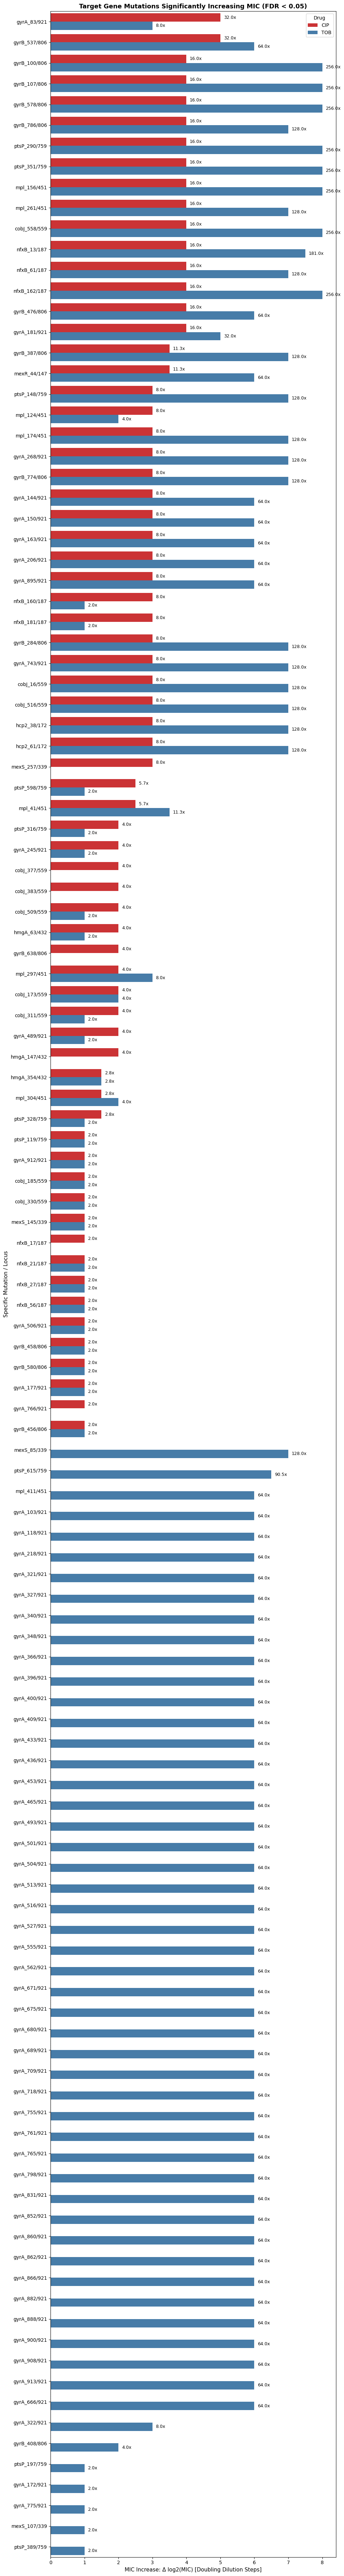

In [23]:
if not sig_increasing_muts.empty:
    plt.figure(figsize=(10, max(4, len(sig_increasing_muts) * 0.4)))
    
    # Barplot showing delta_log2_mic shift per mutation
    ax = sns.barplot(
        data=sig_increasing_muts,
        x='delta_log2_mic',
        y='Locus',
        hue='Drug',
        palette={'CIP': '#e41a1c', 'TOB': '#377eb8'}
    )
    
    plt.title('Target Gene Mutations Significantly Increasing MIC (FDR < 0.05)', fontsize=13, fontweight='bold')
    plt.xlabel('MIC Increase: Δ log2(MIC) [Doubling Dilution Steps]', fontsize=11)
    plt.ylabel('Specific Mutation / Locus', fontsize=11)
    plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
    
    # Annotate bars with fold-change values
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            fold = 2 ** width
            ax.annotate(
                f'{fold:.1f}x', 
                (width + 0.1, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=9, color='black'
            )
            
    plt.tight_layout()
    plt.show()
else:
    print("No individual locus-level mutations met the FDR < 0.05 and delta_log2_mic > 0 criteria.")

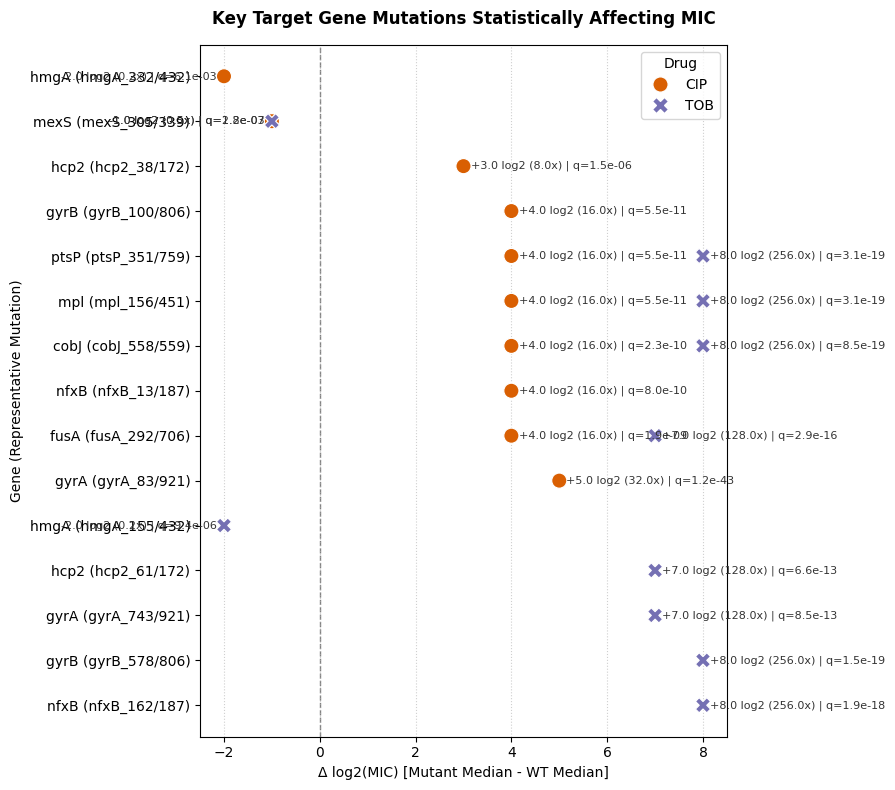

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_genes = [
    "hmgA", "mpl", "hcp2", 
    "PA14_12490", "gyrA", "gyrB", "mexS", 
    "nfxB", "fusA", "cobJ", "orfN", "ptsP"
]

# 1. Filter stats_df for target genes & significant results (FDR < 0.05)
sig_target_muts = stats_df[
    (stats_df['Gene'].isin(target_genes)) & 
    (stats_df['fdr_qval'] < 0.05)
].copy()

# 2. Pick top mutation per Gene/Drug combination (sorted by statistical significance or effect size)
top_muts = (
    sig_target_muts.sort_values(by=['fdr_qval', 'delta_log2_mic'], ascending=[True, False])
    .groupby(['Drug', 'Gene'])
    .head(1)  # Change to head(2) or head(3) if you want top 2-3 per gene
    .reset_index(drop=True)
)

# Sort for orderly plotting
top_muts['Gene_Locus'] = top_muts['Gene'] + " (" + top_muts['Locus'] + ")"
top_muts = top_muts.sort_values(by=['Drug', 'delta_log2_mic'], ascending=[True, True])

# 3. Clean Forest-style Plot
plt.figure(figsize=(9, max(4, len(top_muts) * 0.4)))

# Plot points for effect size
sns.scatterplot(
    data=top_muts,
    x='delta_log2_mic',
    y='Gene_Locus',
    hue='Drug',
    style='Drug',
    s=120,
    palette={'CIP': '#d95f02', 'TOB': '#7570b3'},
    zorder=3
)

# Add reference line at zero impact
plt.axvline(0, color='gray', linestyle='--', linewidth=1, zorder=1)

# Annotate each point with exact fold-change & q-value
for idx, row in top_muts.iterrows():
    fold = 2 ** row['delta_log2_mic']
    sign = "+" if row['delta_log2_mic'] > 0 else ""
    label = f"{sign}{row['delta_log2_mic']:.1f} log2 ({fold:.1f}x) | q={row['fdr_qval']:.1e}"
    
    # Place text dynamically based on positive/negative shift
    x_pos = row['delta_log2_mic'] + (0.15 if row['delta_log2_mic'] >= 0 else -0.15)
    ha = 'left' if row['delta_log2_mic'] >= 0 else 'right'
    
    plt.text(
        x_pos, row['Gene_Locus'], label, 
        va='center', ha=ha, fontsize=8, color='#333333'
    )

plt.title("Key Target Gene Mutations Statistically Affecting MIC", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Δ log2(MIC) [Mutant Median - WT Median]", fontsize=10)
plt.ylabel("Gene (Representative Mutation)", fontsize=10)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

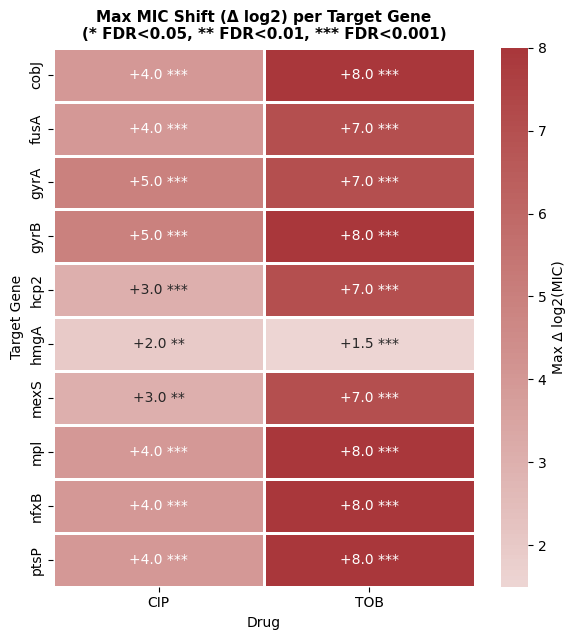

In [25]:
# Pivot data into a matrix: Genes vs Drugs (showing delta_log2_mic)
pivot_effect = sig_target_muts.pivot_table(
    index='Gene', 
    columns='Drug', 
    values='delta_log2_mic', 
    aggfunc='max'  # Shows max effect if multiple mutations exist per gene
)

pivot_fdr = sig_target_muts.pivot_table(
    index='Gene', 
    columns='Drug', 
    values='fdr_qval', 
    aggfunc='min'
)

# Prepare annotation strings (e.g., "+2.1*")
annot_matrix = pivot_effect.copy().astype(str)
for gene in pivot_effect.index:
    for drug in pivot_effect.columns:
        val = pivot_effect.loc[gene, drug]
        fdr = pivot_fdr.loc[gene, drug]
        if pd.isna(val):
            annot_matrix.loc[gene, drug] = ""
        else:
            stars = "***" if fdr < 0.001 else ("**" if fdr < 0.01 else "*")
            annot_matrix.loc[gene, drug] = f"{val:+.1f} {stars}"

# Plot Heatmap
plt.figure(figsize=(6, len(pivot_effect) * 0.5 + 1.5))
sns.heatmap(
    pivot_effect,
    annot=annot_matrix,
    fmt="",
    cmap="vlag",
    center=0,
    cbar_kws={'label': 'Max Δ log2(MIC)'},
    linewidths=1,
    linecolor='white'
)

plt.title("Max MIC Shift (Δ log2) per Target Gene\n(* FDR<0.05, ** FDR<0.01, *** FDR<0.001)", fontsize=11, fontweight='bold')
plt.xlabel("Drug")
plt.ylabel("Target Gene")
plt.tight_layout()
plt.show()

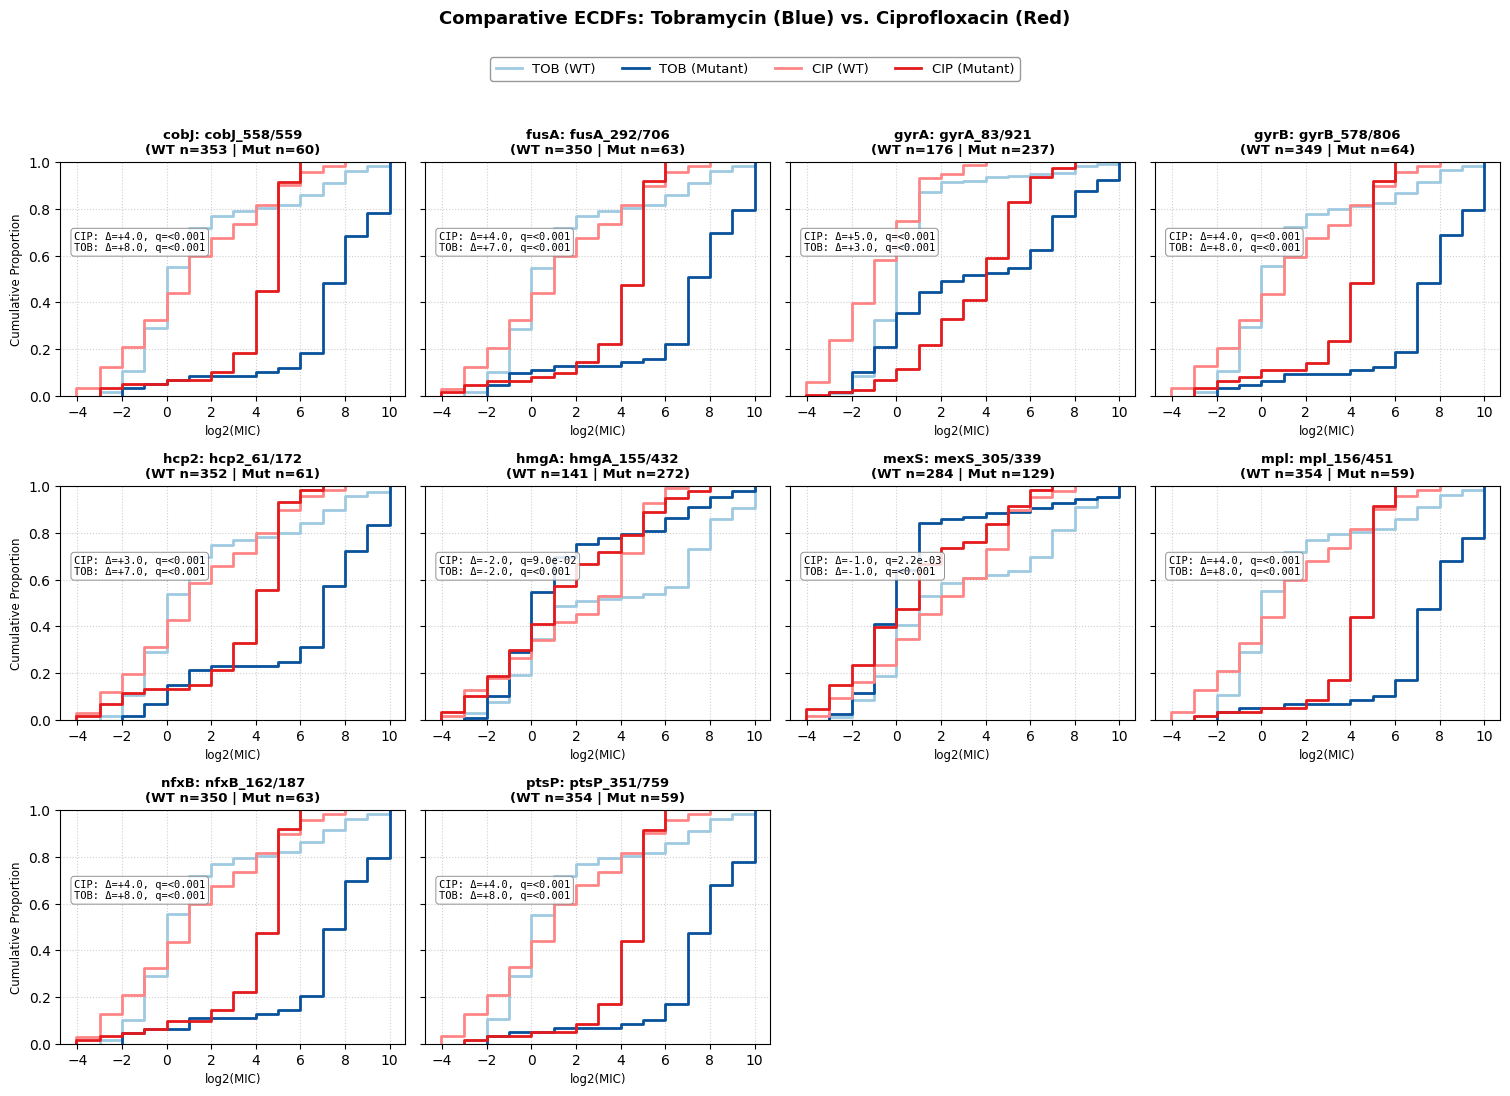

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

target_genes_ = [
    "hmgA", "mpl", "hcp2", 
    "PA14_12490", "gyrA", "gyrB", "mexS", 
    "nfxB", "fusA", "cobJ", "orfN", "ptsP"
]

def extract_gene_name(locus_str):
    if pd.isna(locus_str):
        return locus_str
    if locus_str.startswith('PA14_'):
        parts = locus_str.split('_')
        return f"{parts[0]}_{parts[1]}"
    return locus_str.split('_')[0]

def plot_dual_drug_ecdfs_vibrant(stats_data, df_data, target_genes_list, fdr_cutoff=0.05, ncols=4):
    stats_data = stats_data.copy()
    stats_data['Gene'] = stats_data['Locus'].apply(extract_gene_name)

    # 1. Select top loci passing FDR cutoff for at least one drug
    sig_stats = stats_data[
        (stats_data['Gene'].isin(target_genes_list)) & 
        (stats_data['fdr_qval'] < fdr_cutoff)
    ].copy()

    if sig_stats.empty:
        print(f"No significant loci found across either drug at FDR < {fdr_cutoff}")
        return

    top_loci = (
        sig_stats.sort_values(by=['fdr_qval', 'p_value'])
        .groupby('Gene')
        .first()
        .reset_index()
    )

    nrows = int(np.ceil(len(top_loci) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.8, nrows * 3.4), sharey=True)
    
    if nrows == 1 and ncols == 1:
        axes = np.array([axes])
    else:
        axes = np.array(axes).reshape(-1)

    # Color definitions: Light/Dark Blue (TOB) and Light Coral / Vibrant Red (CIP)
    style_palette = {
        'TOB_WT':     '#9ecae1',  # Soft Blue
        'TOB_Mutant': '#08519c',  # Dark Navy Blue
        'CIP_WT':     '#ff8585',  # Light Coral Pink
        'CIP_Mutant': '#e41a1c'   # Vibrant Crimson Red
    }

    for idx, row in top_loci.iterrows():
        ax = axes[idx]
        locus_col = row['Locus']
        gene_name = row['Gene']
        
        if locus_col not in df_data.columns:
            ax.set_title(f"{locus_col}\n(Column missing in df)", fontsize=9)
            continue

        cols_needed = [locus_col, 'TOB_log2', 'CIP_log2']
        sub = df_data[[c for c in cols_needed if c in df_data.columns]].dropna().copy()
        
        wt_n = (sub[locus_col] == 0).sum()
        mut_n = (sub[locus_col] == 1).sum()

        # Plot Tobramycin (TOB) — Solid Lines
        if 'TOB_log2' in sub.columns:
            for status, color in [(0, style_palette['TOB_WT']), (1, style_palette['TOB_Mutant'])]:
                data_subset = sub[sub[locus_col] == status]['TOB_log2']
                if not data_subset.empty:
                    sns.ecdfplot(data=data_subset, color=color, linewidth=2, ax=ax)

        # Plot Ciprofloxacin (CIP) — Solid Lines
        if 'CIP_log2' in sub.columns:
            for status, color in [(0, style_palette['CIP_WT']), (1, style_palette['CIP_Mutant'])]:
                data_subset = sub[sub[locus_col] == status]['CIP_log2']
                if not data_subset.empty:
                    sns.ecdfplot(data=data_subset, color=color, linewidth=2, ax=ax)

        ax.set_title(f"{gene_name}: {locus_col}\n(WT n={wt_n} | Mut n={mut_n})", fontsize=9.5, fontweight='bold')
        ax.set_xlabel("log2(MIC)", fontsize=8.5)
        if idx % ncols == 0:
            ax.set_ylabel("Cumulative Proportion", fontsize=8.5)
        ax.grid(True, linestyle=':', alpha=0.6)

        # Extract stats for BOTH CIP and TOB for this specific locus
        locus_stats = stats_data[stats_data['Locus'] == locus_col]
        
        stats_str_list = []
        for drug_code, drug_label in [('CIP', 'CIP'), ('TOB', 'TOB')]:
            d_stat = locus_stats[locus_stats['Drug'] == drug_code]
            if not d_stat.empty:
                d_row = d_stat.iloc[0]
                q_v = d_row['fdr_qval']
                delta_m = d_row['delta_log2_mic']
                q_fmt = f"{q_v:.1e}" if q_v >= 0.001 else "<0.001"
                stats_str_list.append(f"{drug_label}: Δ={delta_m:+.1f}, q={q_fmt}")

        if stats_str_list:
            stats_text = "\n".join(stats_str_list)
            ax.text(
                0.04, 0.62, stats_text, transform=ax.transAxes,
                fontsize=7.5, fontfamily='monospace',
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=0.7, alpha=0.85)
            )

    # Hide unused axes
    for idx in range(len(top_loci), len(axes)):
        fig.delaxes(axes[idx])

    # Construct single shared global legend
    legend_elements = [
        Line2D([0], [0], color=style_palette['TOB_WT'], lw=2, label='TOB (WT)'),
        Line2D([0], [0], color=style_palette['TOB_Mutant'], lw=2, label='TOB (Mutant)'),
        Line2D([0], [0], color=style_palette['CIP_WT'], lw=2, label='CIP (WT)'),
        Line2D([0], [0], color=style_palette['CIP_Mutant'], lw=2, label='CIP (Mutant)'),
    ]

    fig.legend(
        handles=legend_elements,
        loc='upper center',
        bbox_to_anchor=(0.5, 1.03),
        ncol=4,
        frameon=True,
        facecolor='white',
        edgecolor='gray',
        fontsize=9.5
    )

    plt.suptitle("Comparative ECDFs: Tobramycin (Blue) vs. Ciprofloxacin (Red)", fontsize=13, fontweight='bold', y=1.07)
    plt.tight_layout()
    figpath = base_dir / repo_name / 'figures' / "figure_6.png"
    plt.savefig(figpath, dpi=300, bbox_inches='tight')
    plt.show()

# Run combined plot
plot_dual_drug_ecdfs_vibrant(stats_df, df, target_genes, fdr_cutoff=0.05)


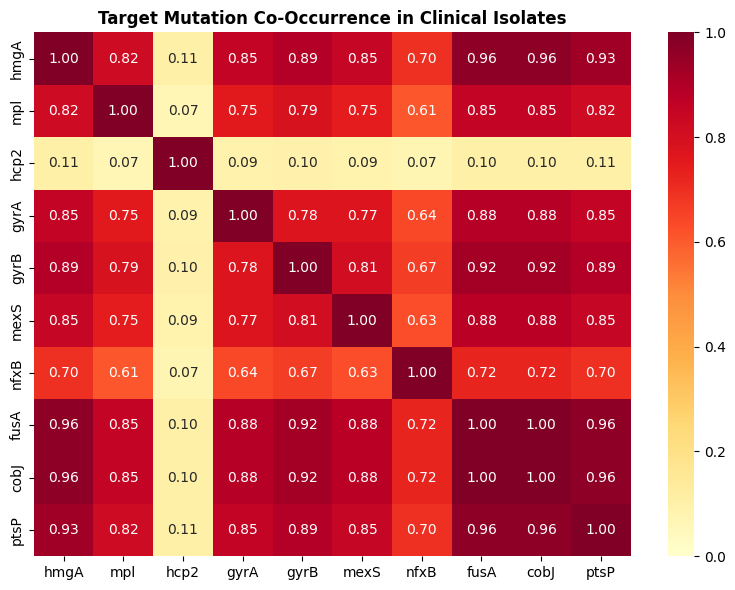

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Get binary columns for target genes
target_cols = [f'{g}_any_mut' for g in target_genes if f'{g}_any_mut' in df.columns]

# Calculate co-occurrence (phi coefficient / correlation)
co_occurrence = df[target_cols].corr()

# Clean labels for plot
clean_labels = [c.replace('_any_mut', '') for c in target_cols]

plt.figure(figsize=(8, 6))
sns.heatmap(
    co_occurrence, 
    xticklabels=clean_labels, 
    yticklabels=clean_labels,
    annot=True, 
    fmt=".2f", 
    cmap="YlOrRd",
    vmin=0, vmax=1
)
plt.title("Target Mutation Co-Occurrence in Clinical Isolates", fontweight='bold')
plt.tight_layout()
plt.show()

In [28]:
import statsmodels.api as sm

# Prepare data for multivariable regression
for drug in ['CIP', 'TOB']:
    log2_col = f'{drug}_log2'
    
    # Subset complete cases
    model_data = df.dropna(subset=[log2_col] + target_cols).copy()
    
    X = model_data[target_cols]
    X = sm.add_constant(X)  # Baseline (WT across all target genes)
    y = model_data[log2_col]
    
    # Fit OLS model
    model = sm.OLS(y, X).fit()
    
    print(f"==========================================")
    print(f" Multivariable Model: Independent Effects on {drug} MIC")
    print(f"==========================================")
    
    # Clean output summary
    summary_df = pd.DataFrame({
        'Coefficient (log2 shift)': model.params,
        'Std Error': model.bse,
        'p-value': model.pvalues
    })
    
    # Clean index names
    summary_df.index = [i.replace('_any_mut', '') for i in summary_df.index]
    print(summary_df.round(3).to_string())

 Multivariable Model: Independent Effects on CIP MIC
       Coefficient (log2 shift)  Std Error  p-value
const                    -1.889      0.973    0.053
hmgA                      5.394      2.923    0.066
mpl                       2.048      1.315    0.120
hcp2                      1.784      0.342    0.000
gyrA                      5.222      1.945    0.008
gyrB                      3.889      2.281    0.089
mexS                      0.281      1.466    0.848
nfxB                      1.031      0.856    0.229
fusA                     -8.988      2.737    0.001
cobJ                     -8.988      2.737    0.001
ptsP                      3.335      2.923    0.255
 Multivariable Model: Independent Effects on TOB MIC
       Coefficient (log2 shift)  Std Error  p-value
const                    -0.222      1.141    0.846
hmgA                      4.560      3.428    0.184
mpl                       3.033      1.542    0.050
hcp2                      3.682      0.401    0.000
gyrA      

In [29]:
# Identify strains with EXACTLY 1 target mutation
df['target_mut_sum'] = df[target_cols].sum(axis=1)

# Function to label isolate genotype state
def classify_genotype(row):
    total = row['target_mut_sum']
    if total == 0:
        return 'WT (0 target muts)'
    elif total == 1:
        # Find which single gene it is
        for col in target_cols:
            if row[col] == 1:
                return f"Only {col.replace('_any_mut', '')}"
    else:
        return f'Multi-mutant ({total} muts)'

df['mutation_isolation_class'] = df.apply(classify_genotype, axis=1)

# Summary of sample counts and median MICs
for drug in ['CIP', 'TOB']:
    log2_col = f'{drug}_log2'
    summary = df.groupby('mutation_isolation_class')[log2_col].agg(['count', 'median', 'std'])
    print(f"\n=== {drug} MIC Shift by Isolated Genotype ===")
    print(summary.to_string())


=== CIP MIC Shift by Isolated Genotype ===
                          count  median       std
mutation_isolation_class                         
Multi-mutant (10 muts)       90     4.0  2.543951
Multi-mutant (8 muts)        17     0.0  2.813598
Multi-mutant (9 muts)       292     1.0  3.048466
Only gyrA                     3     4.0  3.055050
Only gyrB                     2     2.0  1.414214
WT (0 target muts)            9    -2.0  1.269296

=== TOB MIC Shift by Isolated Genotype ===
                          count  median       std
mutation_isolation_class                         
Multi-mutant (10 muts)       90     7.0  3.938367
Multi-mutant (8 muts)        17     1.0  3.337620
Multi-mutant (9 muts)       292     0.0  3.237256
Only gyrA                     3    -1.0  1.527525
Only gyrB                     2    -1.0  0.000000
WT (0 target muts)            9     0.0  0.833333


C:\Users\jmf7ak\AppData\Local\Temp\ipykernel_36756\3110711215.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['target_mut_sum'] = df[target_cols].sum(axis=1)
C:\Users\jmf7ak\AppData\Local\Temp\ipykernel_36756\3110711215.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['mutation_isolation_class'] = df.apply(classify_genotype, axis=1)


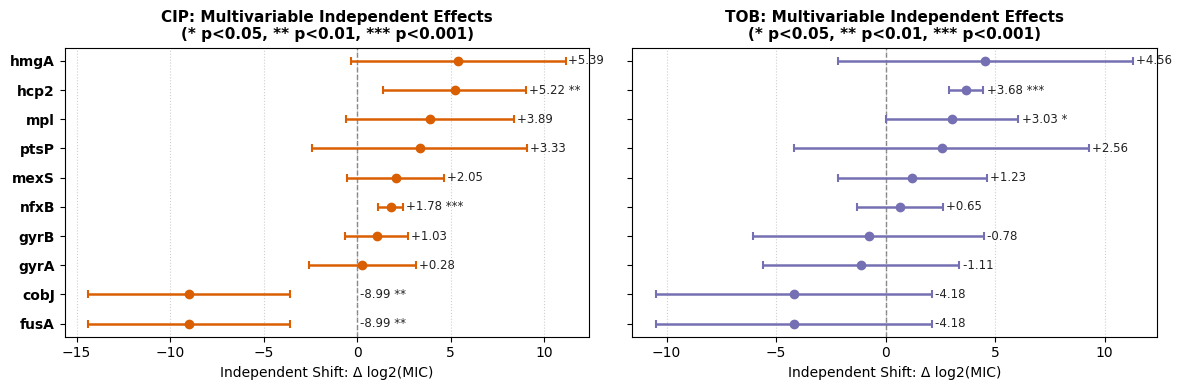

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# 1. Fit Multivariable OLS Models for CIP and TOB
target_cols = [f'{g}_any_mut' for g in target_genes if f'{g}_any_mut' in df.columns]

model_results = []

for drug in ['CIP', 'TOB']:
    log2_col = f'{drug}_log2'
    if log2_col not in df.columns:
        continue

    # Subset complete cases
    model_data = df.dropna(subset=[log2_col] + target_cols).copy()
    if model_data.empty:
        continue

    X = model_data[target_cols]
    X = sm.add_constant(X)
    y = model_data[log2_col]

    # Fit OLS
    model = sm.OLS(y, X).fit()

    # Extract parameters, 95% CIs, and p-values (excluding the intercept)
    conf_int = model.conf_int(alpha=0.05)  # 95% CI
    
    for var in target_cols:
        gene_name = var.replace('_any_mut', '')
        coef = model.params[var]
        ci_lower = conf_int.loc[var, 0]
        ci_upper = conf_int.loc[var, 1]
        p_val = model.pvalues[var]

        model_results.append({
            'Drug': drug,
            'Gene': gene_name,
            'Coef': coef,
            'CI_Lower': ci_lower,
            'CI_Upper': ci_upper,
            'p_value': p_val
        })

coef_df = pd.DataFrame(model_results)

# 2. Create the Forest Plot
drugs = coef_df['Drug'].unique()
fig, axes = plt.subplots(1, len(drugs), figsize=(6 * len(drugs), max(4, len(target_cols) * 0.4)), sharey=True)

if len(drugs) == 1:
    axes = [axes]

drug_colors = {'CIP': '#d95f02', 'TOB': '#7570b3'}

for i, drug in enumerate(drugs):
    ax = axes[i]
    sub = coef_df[coef_df['Drug'] == drug].copy()
    
    # Sort genes consistently across panels
    sub = sub.sort_values(by='Coef', ascending=True)
    
    y_positions = np.arange(len(sub))
    color = drug_colors.get(drug, '#333333')

    # Reference line at 0 (No independent effect)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1, zorder=1)

    # Plot error bars (95% Confidence Intervals)
    err_lower = sub['Coef'] - sub['CI_Lower']
    err_upper = sub['CI_Upper'] - sub['Coef']
    
    ax.errorbar(
        sub['Coef'], 
        y_positions, 
        xerr=[err_lower, err_upper], 
        fmt='o', 
        color=color, 
        ecolor=color, 
        elinewidth=1.8, 
        capsize=3, 
        capthick=1.5, 
        markersize=6, 
        zorder=3
    )

    # Annotate significance and exact effect
    for y_pos, (_, row) in zip(y_positions, sub.iterrows()):
        p_val = row['p_value']
        stars = "***" if p_val < 0.001 else ("**" if p_val < 0.01 else ("*" if p_val < 0.05 else ""))
        label_text = f"{row['Coef']:+.2f} {stars}"
        
        # Place text slightly right of the upper CI limit
        text_x = max(row['CI_Upper'], 0) + 0.15
        ax.text(text_x, y_pos, label_text, va='center', fontsize=8.5, color='#222222')

    ax.set_yticks(y_positions)
    ax.set_yticklabels(sub['Gene'], fontsize=10, fontweight='bold')
    ax.set_xlabel('Independent Shift: Δ log2(MIC)', fontsize=10)
    ax.set_title(f'{drug}: Multivariable Independent Effects\n(* p<0.05, ** p<0.01, *** p<0.001)', fontsize=11, fontweight='bold')
    ax.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()